# 403 – A Variational Quantum Classifier, Built from Scratch

This notebook shows how a **variational quantum circuit** can solve a machine-learning problem —
a binary classification — **without using any QML library**.  Every piece is written by hand:
encoding the data, the trainable circuit, the measurement, the loss, the gradients and the
training loop.  The method is the one proposed by Maria Schuld *et al.* in
[Circuit-centric quantum classifiers](https://arxiv.org/abs/1804.00633).

**Where this fits in the learning path**

| Before | This notebook | After |
|---|---|---|
| `402` – datasets for QML | how a quantum classifier works inside | `410`–`412` – the same idea with `qiskit-machine-learning` |

**You will learn to**
1. encode a classical vector into the amplitudes of a quantum state (*amplitude encoding*);
2. build a layered, parameterised *model circuit* $U(\theta)$;
3. read a class probability from a measurement;
4. compute exact gradients of a circuit with the *Hadamard test*;
5. train the circuit with stochastic gradient descent and draw its decision boundary.

**Prerequisites:** single- and two-qubit gates (`003`, `004`), statevectors (`013`), basic
calculus (derivatives, the chain rule).

### What is a variational circuit ?

In the general case, a variational method is the approximation of an intractable function $f$ (for example solution of a PDE or an optimization problem) by a function $v$, more easily computable. The goal is then to find $v$ that will minimize a specific cost $\mathcal{L}(v)$. The cost function may be expensive to compute, which makes the problem difficult to solve. The idea of using Quantum Computing is to reduce the cost of estimation and in some cases gain an advantage on classical computers.

In our Machine Learning problem, let us suppose we observe $N$ samples of labeled data $(x_i, y_i)_{i \in [1,N]}$ with $x_i \in \mathbb{R}^2$ and $y_i \in \{0,1\}$. The goal of the task is to construct a predictor $f$ to estimate $y$ given a new value of $x$. The problem can be restricted to a set of parameterizable functions by a real vector $\theta$. We will train a model with the training input by finding the parameters $\theta$ that will minimize a loss $l$.

$$\arg\min_{\theta} \frac{1}{N} \sum_{i=1}^{N} l(f(x_i;\theta), y_i)$$

In our case, $f$ will return the probability of $x$ to be labelled $1$. It is then a number comprised between 0 and 1.
The authors use the square loss $l(f(x),y) = (f(x)-y)^2$, another usual loss is the binary crossentropy loss $l(f(x),y) = - y log(f(x)) - (1-y)log(1-f(x))$. In both cases, the farther $f(x)$ is from $y$, the greater the loss.

### The use of quantum computers

The idea of the proposed circuit is to compute $f(x;\theta)$ with a quantum computer, and then to optimize the cost with a classical optimization algorithm, with the hope that it will be more efficient than a full classical algorithm.

Quantum circuits are a very good framework to represent our problem, since the probability of a qubit to be in the state $|0\rangle$ or in the state $|1\rangle$ can be estimated by measurement. 

The circuit is composed of 3 steps: 

- State preparation: encode the classical data $x$ into a quantum circuit by creating an operator $\phi(x)$ which will result in the state $\phi(x) |0_p\rangle$ with $p$ the number of qubits.
- Model circuit: apply an operator $U(\theta)$ to the feature state, with $\theta$ the trainable parameters.
- Measurement: measure the qubit $q_0$ to estimate $f(x;\theta) = \mathbb{P}(q_0=1)$

### State preparation

The classical data need to be converted into a quantum state. A quantum state is a unitary norm vector of complex numbers and can be written $|\psi \rangle = \sum_{i=1}^{n} a_i |i\rangle$ with $\sum_{i=1}^{n} |a_i|^2=1$, and $n=2^p$. Vectors with a power of 2 number of features can be normalized and represented into a quantum state using amplitude encoding, which means that the data are directly associated with the amplitudes of the quantum state. For other number of features, a strategy is to pad with the required number of features to reach a power of 2. The padding features can be zero on non-zero. It can be shown that the encoding can be done linearly with reference to the size of the input vector.

### Model circuit

Given the quantum state $|\phi(x) \rangle$ which represents the vector $x$ in the quantum circuit, we create $U(\theta)$ a unitary operator such that $U(\theta)|\phi(x) \rangle$ is a quantum state we can measure. 

We decompose $U(\theta) = U_1...U_L$ as a product of one or two qubits parametrized gates. In the following we will use a combination of C-NOT gates and general unitary gates whose general formulation is:
$$U(\theta, \phi, \lambda) = \begin{bmatrix}
  cos(\frac{\theta}{2}) & -e^{i\lambda}sin(\frac{\theta}{2})\\ 
  e^{i\phi}sin(\frac{\theta}{2}) & e^{i\lambda+i\phi}cos(\frac{\theta}{2})
\end{bmatrix} 
$$
This parameterization  is chosen because it is the one used by the language Qiskit. The authors of the paper choose another equivalent simpler parameterization, which doesn't need to compute imaginary parts (cf Training section).

### Measurement

The measurement of the 0 qubit of the quantum state $|U(\theta)\phi(x) \rangle$ generated by the previous circuit gives $f(x;\theta) = \mathbb{P}(y|x=1;\theta) = \mathbb{P}(q_0=1|x;\theta) = \sum_{k=1}^{n} |(U(\theta)\phi(x))_k|^2$. For clarity, the explicit dependency of $\theta$ will be removed and we will just note $U$ for $U(\theta)$

Let us denote $\pi(x;\theta) = \mathbb{P}(q_0=1|x;\theta)$. It can also be expressed by the expectancy of the operator $\sigma_z$ applied to the first qubit. $$\mathbb{E}(\sigma_z) = \langle \phi(x)|U^\dagger (\sigma_z \otimes \mathbb{I} \otimes ... \otimes \mathbb{I})U|\phi(x) \rangle$$ and $$\pi(x;\theta) = \frac{-\mathbb{E}(\sigma_z)}{2}+\frac{1}{2}$$.

### Training

The model is trained to minimize a loss function
$$\mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^{N} l(\pi(x_i;\theta), y_i)$$
The parameters are updated via batch stochastic gradient descent. The difficulty is to be able to compute the gradient in an accurate way. Fortunately, as later explained it is possible to evaluate the gradient via quantum circuits.

$$\nabla_\theta\mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^{N} \nabla_\theta(l(\pi(x_i;\theta), y_i)) = \frac{1}{N} \sum_{i=1}^{N} \nabla_\theta\pi(x_i;\theta)\partial_{1}l(\pi(x_i;\theta), y_i)$$

where $\partial_{1}l$ is the partial derivative of $l$ with reference to the first variable.

$$\nabla_\theta\pi(x_i;\theta) = \frac{-\nabla_\theta\mathbb{E}(\sigma_z)}{2} = -\frac{1}{2} \nabla_\theta\langle \phi(x)U \vert \sigma_z \vert U\phi(x) \rangle$$

where $\sigma_z \otimes \mathbb{I} \otimes \dots \otimes \mathbb{I}$ is abbreviated to $\sigma_z$.

Let us now consider $\nu$ an element of the vector $\theta$ and let us examine $\partial_\nu \pi(x;\theta)$:

$$\partial_\nu\pi(x;\theta) = -\frac{1}{2} \langle \phi(x)\partial_\nu U \vert \sigma_z \vert U\phi(x) \rangle -\frac{1}{2} \langle \phi(x)U \vert \sigma_z \vert \partial_\nu U\phi(x) \rangle$$

by the rules of derivation inside an expectation.


$$\partial_\nu\pi(x;\theta) = -\frac{1}{2} (\langle \phi(x)\partial_\nu U| \sigma_z |U\phi(x) \rangle + \langle \phi(x)\partial_\nu U| \sigma_z |U\phi(x) \rangle^*) = - Re\{ \langle \phi(x)\partial_\nu U| \sigma_z |U\phi(x) \rangle\}$$

Generally speaking, $\partial_\nu U$ is not a unitary operator, and therefore cannot be implemented in a quantum circuit. However, due to our circuit architecture, it will be possible.

The derivative of $U$ w.r.t $\nu$ involves only the derivative of the elementary gate to which $\nu$ belongs, due to the factorization of the circuit. It means that $\partial_\nu U = U_1...\partial_\nu(U_i)...U_L$ where $U_i$ is the gate to which $\nu$ belongs.

For an elementary unitary gate as described above, we have the following identities:

$$\partial_\theta U = \frac{1}{2} U(\theta + \pi, \phi, \lambda)$$

$$\partial_\phi U = \frac{i}{2} (U(\theta, \phi, \lambda) - U(\theta, \phi + \pi, \lambda))$$

$$\partial_\lambda U = \frac{i}{2} U(\theta, \phi, \lambda) - U(\theta, \phi, \lambda + \pi))$$

Therefore $\partial_\nu U$ can be computed as the form

$$\sum_{k=1}^{K}a_k \text{Re} \{ \langle \phi(x)U(\theta^{[k]}) \vert \sigma_z \vert U(\theta)\phi(x) \rangle \} + \sum_{l=1}^{L}b_l \text{Im} \{ \langle \phi(x)U(\theta^{[l]}) \vert \sigma_z \vert U(\theta)\phi(x) \rangle \}$$

where $\theta^{[k]}$ and $\theta^{[l]}$ are the modified vector of parameters from the above identities. The imaginary part comes from the $i$ in the same identities for $\phi$ and $\lambda$.


## Implementation

We start with the usual backend set-up cell, then import what we need.  We run on the
shot-based `qasm_simulator`, so every probability we read is an *estimate* from 1000 shots —
just as it would be on real hardware.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector

# `backend` (the shot-based qasm_simulator) was created by the set-up cell above

### Importing and cleaning the data, state preparation

We use two classes of the iris dataset (labels $-1$ / $+1$, which we map to $0$ / $1$) and keep
the first two features.  Amplitude encoding needs a vector of length $2^p$ with unit norm, so
each sample $x=(x_0,x_1)$ is

1. **padded** to length 4 with a constant $0.3$ and a $0$: $(x_0, x_1, 0.3, 0)$ – the constant
   keeps information about the *length* of $x$ that normalisation would otherwise destroy;
2. **normalised** to unit length.

A unit vector of 4 real, non-negative numbers can be prepared on 2 qubits by a cascade of
$R_Y$ rotations and CNOTs (Möttönen *et al.*).  `get_angles` computes the 5 rotation angles; they
become the *features* our circuit actually receives.

In [3]:
def get_angles(x):
    """Rotation angles that prepare the unit vector x = (x0, x1, x2, x3) on two qubits."""
    beta0 = 2 * np.arcsin(np.abs(x[1]) / np.sqrt(x[0] ** 2 + x[1] ** 2 + 1e-12))
    beta1 = 2 * np.arcsin(np.abs(x[3]) / np.sqrt(x[2] ** 2 + x[3] ** 2 + 1e-12))
    beta2 = 2 * np.arcsin(np.sqrt(x[2] ** 2 + x[3] ** 2) / np.linalg.norm(x))
    return np.array([beta2, -beta1 / 2, beta1 / 2, -beta0 / 2, beta0 / 2])

data = np.loadtxt("projects/iris_classes1and2_scaled.txt")
X = data[:, 0:2]
print("First X sample (original)  :", X[0])

# pad the vectors to size 2^2 with constant values
padding = 0.3 * np.ones((len(X), 1))
X_pad = np.c_[np.c_[X, padding], np.zeros((len(X), 1))]
print("First X sample (padded)    :", X_pad[0])

# normalize each input
normalization = np.sqrt(np.sum(X_pad ** 2, -1))
X_norm = (X_pad.T / normalization).T
print("First X sample (normalized):", X_norm[0])

# angles for state preparation are new features
features = np.array([get_angles(x) for x in X_norm])
print("First features sample      :", features[0])

Y = (data[:, -1] + 1) / 2
print("Samples:", len(Y), " class 0:", int(np.sum(Y == 0)), " class 1:", int(np.sum(Y == 1)))

First X sample (original)  : [0.4  0.75]
First X sample (padded)    : [0.4  0.75 0.3  0.  ]
First X sample (normalized): [0.44376016 0.83205029 0.33282012 0.        ]
First features sample      : [ 0.67858523 -0.          0.         -1.080839    1.080839  ]
Samples: 100  class 0: 50  class 1: 50


The state-preparation circuit.  `target[0]` is the *most significant* qubit of the encoded
vector.  Qiskit numbers basis states **little-endian** (qubit 0 is the rightmost bit), so to make
amplitude $k$ of the state equal to $x_k$ we pass the qubits as `[1, 0]`.

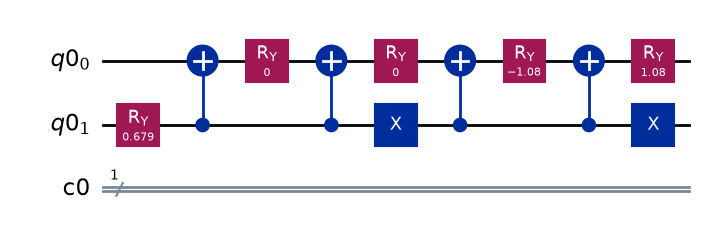

In [4]:
def statepreparation(a, circuit, target):
    """Prepare the amplitudes encoded by the angles a (from get_angles) on qubits target."""
    circuit.ry(a[0], target[0])

    circuit.cx(target[0], target[1])
    circuit.ry(a[1], target[1])
    circuit.cx(target[0], target[1])
    circuit.ry(a[2], target[1])

    circuit.x(target[0])
    circuit.cx(target[0], target[1])
    circuit.ry(a[3], target[1])
    circuit.cx(target[0], target[1])
    circuit.ry(a[4], target[1])
    circuit.x(target[0])

    return circuit

x = X_norm[0]
ang = get_angles(x)
q       = QuantumRegister(2)
c       = ClassicalRegister(1)
circuit = QuantumCircuit(q,c)
circuit = statepreparation(ang, circuit, [1, 0])
circuit.draw(output='mpl')

**Check:** the prepared statevector should reproduce the normalised data vector exactly.

In [5]:
check = QuantumCircuit(2)
statepreparation(get_angles(X_norm[0]), check, [1, 0])
print("data vector      :", X_norm[0].round(4))
print("prepared amplitudes:", Statevector(check).data.real.round(4))
errors = [np.abs(Statevector(statepreparation(get_angles(v), QuantumCircuit(2), [1, 0])).data.real - v).max()
          for v in X_norm]
print(f"largest error over all {len(X_norm)} samples: {max(errors):.2e}")

data vector      : [0.4438 0.8321 0.3328 0.    ]
prepared amplitudes: [ 0.4438  0.8321  0.3328 -0.    ]


largest error over all 100 samples: 1.00e-06


### Preparing the circuit

These helper functions build the *model circuit* $U(\theta)$.  It is a stack of **layers**,
by analogy with the layers of a neural network.  A layer applies a general single-qubit gate
$U(\theta,\phi,\lambda)$ – three parameters – to each of the two qubits, followed by a CNOT whose
direction alternates from layer to layer.  The *controlled* versions (`c_...`) are needed later
for the gradient circuits.

In [6]:
def u_gate(param, circuit, target):
    '''Return the quantum circuit with u3 gate applied on qubit target with param as an iterable'''
    circuit.u(param[0],param[1],param[2],target)
    return circuit

def cu_gate(param, circuit, control, target):
    '''Return the quantum circuit with cu3 gate applied on qubit target with param as an iterable wrt control'''
    circuit.cu(param[0], param[1], param[2], 0, control, target)
    return circuit

def circuit_block(param, circuit, target, same_order_x=True):
    '''Return the block applied on qubits target from the circuit circuit
    - param : array parameters for the two u gate
    - target : array of integer the numero of qubits for the u gates to be applied
    - if same_order_x == True : cx(target[0], target[1])
    else: cx(target[1], target[0])'''
    circuit = u_gate(param[0], circuit, target[0])
    circuit = u_gate(param[1], circuit, target[1])
    if same_order_x:
        circuit.cx(target[0], target[1])
    else:
        circuit.cx(target[1], target[0])
    return circuit

def c_circuit_block(param, circuit, control, target, same_order_x=True):
    '''Return the controlled block applied on qubits target from the circuit circuit
    - param : array parameters for the two u gate
    - target : array of integer the numero of qubits for the u gates to be applied
    - if same_order_x == True : cx(target[0], target[1])
    else: cx(target[1], target[0])'''
    circuit = cu_gate(param[0], circuit, control, target[0])
    circuit = cu_gate(param[1], circuit, control, target[1])
    if same_order_x:
        circuit.ccx(control, target[0], target[1])
    else:
        circuit.ccx(control, target[1], target[0])
    return circuit

def create_circuit(param, circuit, target):
    order = True
    for i in range(param.shape[0]):
        circuit = circuit_block(param[i], circuit, target, order)
        order = not order
    return circuit

def create_c_circuit(param, circuit, control, target):
    order = True
    for i in range(param.shape[0]):
        circuit = c_circuit_block(param[i], circuit, control, target, order)
        order = not order 
    return circuit

The full circuit for one sample: state preparation, then 4 model layers, then a measurement of qubit 0.

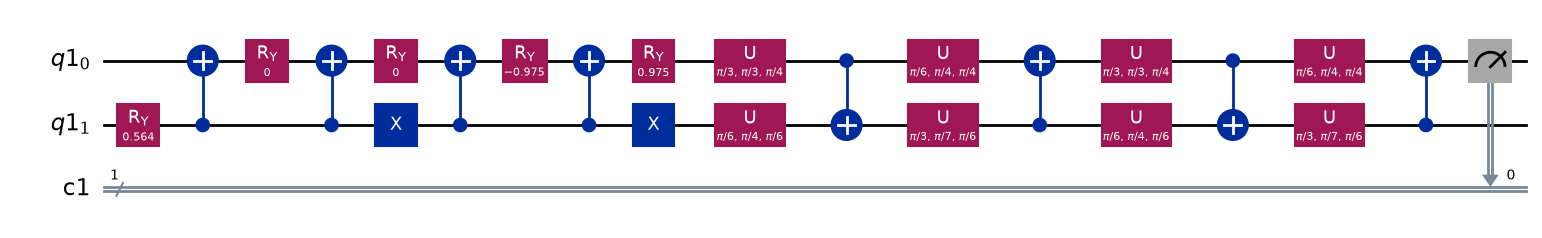

In [7]:
x = np.array([0.53896774, 0.79503606, 0.27826503, 0.0])
ang = get_angles(x)

params = np.array([[[np.pi/3,np.pi/3,np.pi/4],
                    [np.pi/6,np.pi/4,np.pi/6]],
                    [[np.pi/6,np.pi/4,np.pi/4],
                    [np.pi/3,np.pi/7,np.pi/6]],
                    [[np.pi/3,np.pi/3,np.pi/4],
                    [np.pi/6,np.pi/4,np.pi/6]],
                    [[np.pi/6,np.pi/4,np.pi/4],
                    [np.pi/3,np.pi/7,np.pi/6]]])

q       = QuantumRegister(2)
c       = ClassicalRegister(1)
circuit = QuantumCircuit(q,c)
circuit = statepreparation(ang, circuit, [1, 0])

circuit = create_circuit(params, circuit, [0,1])

circuit.measure(0,c)

circuit.draw(output='mpl')

`execute_circuit` runs the circuit and returns the estimated probability
$\pi(x;\theta)=\mathbb{P}(q_0=1)$, plus a trainable classical **bias** $b$.

In [8]:
def execute_circuit(params, angles=None, x=None, use_angles=True, bias=0, shots=1000):
    if not use_angles:
        angles = get_angles(x)
    q       = QuantumRegister(2)
    c       = ClassicalRegister(1)
    circuit = QuantumCircuit(q,c)
    circuit = statepreparation(angles, circuit, [1, 0])

    circuit = create_circuit(params, circuit, [0,1])
    circuit.measure(0,c)
    result = execute(circuit,backend,shots=shots).result()

    counts = result.get_counts(circuit)
    result=np.zeros(2)
    for key in counts:
        result[int(key,2)]=counts[key]
    result/=shots
    return result[1] + bias

execute_circuit(params, ang, bias=0.02)

np.float64(0.724)

### Cost and accuracy functions

* prediction: class 1 if $\pi \ge 0.5$, else class 0;
* **square loss** $\;l = (y-\pi)^2$ – the cost we train on, as the authors of the paper do;
* binary cross entropy $\;l = -y\log\pi - (1-y)\log(1-\pi)$ – the usual choice for classifiers,
  shown for comparison (exercise 4 explains why we do not train on it here);
* accuracy – the fraction of correctly predicted labels.

In [9]:
def predict(probas):
    return (probas >= 0.5) * 1

def binary_crossentropy(labels, predictions):
    loss = 0
    for l, p in zip(labels, predictions):
        p = np.clip(p, 1e-8, 1 - 1e-8)
        loss = loss - l * np.log(p) - (1 - l) * np.log(1 - p)
    return loss / len(labels)

def square_loss(labels, predictions):
    loss = 0
    for l, p in zip(labels, predictions):
        loss = loss + (l - p) ** 2
    return loss / len(labels)

def cost(params, features, labels, bias=0):
    predictions = [execute_circuit(params, angles=f, bias=bias) for f in features]
    return square_loss(labels, predictions)

def accuracy(labels, predictions):
    correct = 0
    for l, p in zip(labels, predictions):
        if abs(l - p) < 1e-5:
            correct = correct + 1
    return correct / len(labels)

### Computing the gradients

The following routines will compute $Re\{ \langle \phi(x)U(\theta^{[k]})| \sigma_z |U(\theta)\phi(x) \rangle\}$ and $Im\{ \langle \phi(x)U(\theta^{[l]})| \sigma_z |U(\theta)\phi(x) \rangle\}$ for given parameters $\theta^{[k]}$, $\theta^{[l]}$ and $\theta$.

Let us assume we can prepare two unitary states $|A\rangle$ and $|B\rangle$ (result of an action of unitary operators $A$ and $B$ on $|0_p\rangle$) conditioned to the state of an ancilla qubit $a$, that is the state 
$$ \frac{|0\rangle|A\rangle + |1\rangle|B\rangle}{\sqrt{2}}$$

Applying a Hadamard to the ancilla leads to 
$$ \frac{|0\rangle(|A\rangle+|B\rangle) + |1\rangle(|A\rangle-|B\rangle)}{2}$$

$\mathbb{P}(a=0) = (|A\rangle+|B\rangle)^\dagger(|A\rangle+|B\rangle) = \frac{1}{4}(2 + \langle A|B\rangle + \langle B|A\rangle) = \frac{1}{2} + \frac{1}{2}Re(\langle A|B\rangle)$. By measuring the ancilla, it is then possible to obtain $Re(\langle A|B\rangle)$.

To compute $Im(\langle A|B\rangle)$, the procedure is very similar. We prepare the state 
$$ \frac{|0\rangle|A\rangle + i|1\rangle|B\rangle}{\sqrt{2}}$$
This can be done by applying a $U(0,0,\pi/2)$ gate to the ancilla. We then apply a Hadamard to the ancilla, and we have $\mathbb{P}(a=0) = \frac{1}{2} - \frac{1}{2}Im(\langle A|B\rangle)$

**How to prepare the initial conditioned state?**

We start with $p$ qubits and an ancilla, and apply a Hadamard gate to the ancilla. It leads to the state
$$\frac{|0\rangle|0_p\rangle + |1\rangle|0_p\rangle}{\sqrt{2}}$$

We apply $B$ controlled by the ancilla to the $p$ qubits, which is
$$\frac{|0\rangle|0_p\rangle + |1\rangle|B\rangle}{\sqrt{2}}$$

We flip the ancilla
$$\frac{|1\rangle|0_p\rangle + |0\rangle|B\rangle}{\sqrt{2}}$$

We apply $A$ controlled by the ancilla to the $p$ qubits
$$\frac{|1\rangle|A\rangle + |0\rangle|B\rangle}{\sqrt{2}}$$

We flip again the ancilla
$$\frac{|0\rangle|A\rangle + |1\rangle|B\rangle}{\sqrt{2}}$$

In [10]:
def real(param1, param2, angles, shots=1000):
    """Returns Re{<circuit(param2)|sigma_z|circuit(param1)>}"""
    q = QuantumRegister(3)
    c = ClassicalRegister(1)
    circuit = QuantumCircuit(q,c)
    circuit.h(q[0])
    circuit = statepreparation(angles, circuit, [2, 1])
    circuit = create_c_circuit(param1, circuit, 0, [1,2])
    circuit.cz(q[0], q[1])
    circuit.x(q[0])
    circuit = create_c_circuit(param2, circuit, 0, [1,2])
    circuit.x(q[0])
    circuit.h(q[0])
    circuit.measure(q[0],c)
    result = execute(circuit,backend,shots=shots).result()
    counts = result.get_counts(circuit)
    result=np.zeros(2)
    for key in counts:
        result[int(key,2)]=counts[key]
    result/=shots
    return (2*result[0]-1)

def imaginary(param1, param2, angles, shots=1000):
    """Returns Im{<circuit(param2)|sigma_z|circuit(param1)>}"""
    q = QuantumRegister(3)
    c = ClassicalRegister(1)
    circuit = QuantumCircuit(q,c)
    circuit.h(q[0])
    circuit = statepreparation(angles, circuit, [2, 1])
    circuit = create_c_circuit(param1, circuit, 0, [1,2])
    circuit.cz(q[0], q[1])
    circuit.x(q[0])
    circuit = create_c_circuit(param2, circuit, 0, [1,2])
    circuit.x(q[0])
    circuit.p(np.pi/2, q[0])
    circuit.h(q[0])
    circuit.measure(q[0],c)
    result = execute(circuit,backend,shots=shots).result()
    counts = result.get_counts(circuit)
    result=np.zeros(2)
    for key in counts:
        result[int(key,2)]=counts[key]
    result/=shots
    return -(2*result[0]-1)

`gradients` combines the Hadamard-test estimates into $\partial\pi/\partial\nu$ for every
parameter $\nu$, then multiplies by $\partial l/\partial\pi = 2(\pi-y)$ (the derivative of
the square loss) – the chain rule from the *Training* section.  The same factor is the
gradient for the bias $b$, because $\partial\pi/\partial b = 1$.

> We checked this implementation against finite differences on an exact simulator: the
> Hadamard-test gradients agree to numerical precision.  On the shot-based simulator they carry
> a small statistical error, which stochastic gradient descent tolerates well.

In [11]:
def gradients(params, angles, label, bias=0):
    grads = np.zeros_like(params)
    imag = imaginary(params, params, angles)
    for i in range(params.shape[0]):
        for j in range(params.shape[1]):
            params_bis = np.copy(params)
            
            params_bis[i,j,0]+=np.pi
            grads[i,j,0] = -0.5 * real(params, params_bis, angles)
            params_bis[i,j,0]-=np.pi
            
            params_bis[i,j,1]+=np.pi
            grads[i,j,1] = 0.5 * (imaginary(params, params_bis, angles) - imag)
            params_bis[i,j,1]-=np.pi
            
            params_bis[i,j,2]+=np.pi
            grads[i,j,2] = 0.5 * (imaginary(params, params_bis, angles) - imag)
            params_bis[i,j,2]-=np.pi
    p = execute_circuit(params, angles, bias=bias) 
    grad_bias = 2 * (p - label)   # derivative of the square loss (p - label)^2
    grads *= grad_bias
    return grads, grad_bias
            

### Training of the model

75 % of the samples are used for training, the rest for validation.  Each iteration draws a
mini-batch of 5 samples, estimates the gradient, and takes one step of **gradient descent with
Nesterov momentum**.

The weights start as random angles of size ~0.5 rad.  Starting them all near 0 would put every
gate close to the identity – a *saddle point* where all gradients vanish and training barely
moves (try it: exercise 5).

Every iteration runs a few hundred circuits, so expect roughly 3–4 minutes.

In [12]:
np.random.seed(0)
num_data = len(Y)
num_train = int(0.75 * num_data)
index = np.random.permutation(range(num_data))
feats_train = features[index[:num_train]]
Y_train = Y[index[:num_train]]
feats_val = features[index[num_train:]]
Y_val = Y[index[num_train:]]

# We need these later for plotting
X_train = X[index[:num_train]]
X_val = X[index[num_train:]]

In [13]:
np.random.seed(0)
layers = 6
params_init = np.random.randn(layers, 2, 3) * 0.5
bias_init = 0.0
batch_size = 5
learning_rate = 0.02
momentum = 0.9

var = np.copy(params_init)
bias = bias_init
v = np.zeros_like(var)
v_bias = 0
history = []
start = time.time()

for it in range(25):

    # Update the weights by one optimizer step (Nesterov momentum)
    batch_index = np.random.randint(0, num_train, (batch_size,))
    feats_train_batch = feats_train[batch_index]
    Y_train_batch = Y_train[batch_index]
    grads = np.zeros_like(var)
    grad_bias = 0
    var_corrected = var + momentum * v
    bias_corrected = bias + momentum * v_bias
    for j in range(batch_size):
        g, g_bias = gradients(var_corrected, feats_train_batch[j], Y_train_batch[j], bias_corrected)
        grads += g / batch_size
        grad_bias += g_bias / batch_size

    v = momentum * v - learning_rate * grads
    v_bias = momentum * v_bias - learning_rate * grad_bias

    var += v
    bias += v_bias

    # Compute predictions on train and validation set
    probas_train = np.array([execute_circuit(var, angles=f, bias=bias) for f in feats_train])
    probas_val = np.array([execute_circuit(var, angles=f, bias=bias) for f in feats_val])
    predictions_train = predict(probas_train)
    predictions_val = predict(probas_val)

    # Compute accuracy on train and validation set
    acc_train = accuracy(Y_train, predictions_train)
    acc_val = accuracy(Y_val, predictions_val)
    loss = square_loss(Y_train, probas_train)
    history.append((loss, acc_train, acc_val))

    print(
        "Iter: {:5d} | Loss (train): {:0.4f} | Acc train: {:0.3f} | Acc validation: {:0.3f} "
        "".format(it + 1, loss, acc_train, acc_val)
    )
print(f"training time: {time.time() - start:.0f} s")

Iter:     1 | Loss (train): 0.4457 | Acc train: 0.240 | Acc validation: 0.320 


Iter:     2 | Loss (train): 0.4203 | Acc train: 0.133 | Acc validation: 0.200 


Iter:     3 | Loss (train): 0.3962 | Acc train: 0.040 | Acc validation: 0.000 


Iter:     4 | Loss (train): 0.3793 | Acc train: 0.067 | Acc validation: 0.120 


Iter:     5 | Loss (train): 0.3652 | Acc train: 0.507 | Acc validation: 0.440 


Iter:     6 | Loss (train): 0.3468 | Acc train: 0.520 | Acc validation: 0.440 


... (15 outputs left out)

Iter:    22 | Loss (train): 0.0726 | Acc train: 0.960 | Acc validation: 1.000 


Iter:    23 | Loss (train): 0.0727 | Acc train: 0.973 | Acc validation: 1.000 


Iter:    24 | Loss (train): 0.0686 | Acc train: 0.987 | Acc validation: 1.000 


Iter:    25 | Loss (train): 0.0671 | Acc train: 1.000 | Acc validation: 1.000 
training time: 250 s


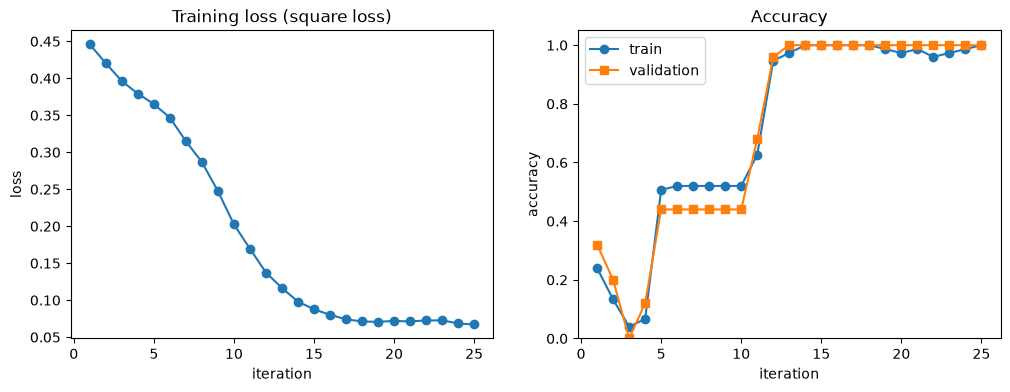

In [14]:
history = np.array(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, len(history) + 1), history[:, 0], 'o-')
ax1.set(title='Training loss (square loss)', xlabel='iteration', ylabel='loss')
ax2.plot(range(1, len(history) + 1), history[:, 1], 'o-', label='train')
ax2.plot(range(1, len(history) + 1), history[:, 2], 's-', label='validation')
ax2.set(title='Accuracy', xlabel='iteration', ylabel='accuracy', ylim=(0, 1.05))
ax2.legend()
plt.show()

### Plot of the results

We evaluate the trained circuit on a grid of input points.  Colours show the predicted
probability of class 1; the dashed line is the **decision boundary** $\pi = 0.5$.

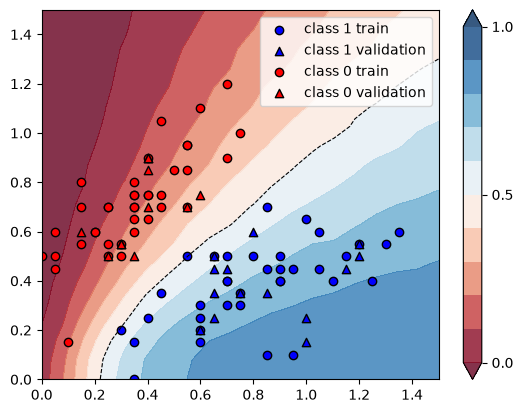

In [15]:
plt.figure()
cm = plt.cm.RdBu

# make data for decision regions
xx, yy = np.meshgrid(np.linspace(0.0, 1.5, 20), np.linspace(0.0, 1.5, 20))
X_grid = [np.array([x, y]) for x, y in zip(xx.flatten(), yy.flatten())]

# preprocess grid points like data inputs above
padding = 0.3 * np.ones((len(X_grid), 1))
X_grid = np.c_[np.c_[X_grid, padding], np.zeros((len(X_grid), 1))]  # pad each input
normalization = np.sqrt(np.sum(X_grid ** 2, -1))
X_grid = (X_grid.T / normalization).T  # normalize each input
features_grid = np.array(
    [get_angles(x) for x in X_grid]
)  # angles for state preparation are new features
predictions_grid = [execute_circuit(var, angles=f, bias=bias, shots=10000) for f in features_grid]
Z = np.reshape(predictions_grid, xx.shape)

# plot decision regions
cnt = plt.contourf(xx, yy, Z, levels=np.arange(0, 1.1, 0.1), cmap=cm, alpha=0.8, extend="both")
plt.contour(xx, yy, Z, levels=[0.5], colors=("black",), linestyles=("--",), linewidths=(0.8,))
plt.colorbar(cnt, ticks=[0, 0.5, 1])

# plot data
plt.scatter(
    X_train[:, 0][Y_train == 1],
    X_train[:, 1][Y_train == 1],
    c="b",
    marker="o",
    edgecolors="k",
    label="class 1 train",
)
plt.scatter(
    X_val[:, 0][Y_val == 1],
    X_val[:, 1][Y_val == 1],
    c="b",
    marker="^",
    edgecolors="k",
    label="class 1 validation",
)
plt.scatter(
    X_train[:, 0][Y_train == 0],
    X_train[:, 1][Y_train == 0],
    c="r",
    marker="o",
    edgecolors="k",
    label="class 0 train",
)
plt.scatter(
    X_val[:, 0][Y_val == 0],
    X_val[:, 1][Y_val == 0],
    c="r",
    marker="^",
    edgecolors="k",
    label="class 0 validation",
)

plt.legend()
plt.show()

## Key takeaways

* A quantum classifier = **data encoding** $\phi(x)$ + **trainable circuit** $U(\theta)$ +
  **measurement** – trained by a classical optimiser.  This *hybrid* loop is the heart of
  nearly all near-term QML.
* Gradients of a circuit can be measured **on the quantum computer itself** (here with the
  Hadamard test; the libraries in the next notebooks use the closely related *parameter-shift
  rule*).
* Everything is estimated from shots, so losses and accuracies fluctuate a little from run to run.

## Try it yourself
1. Change `layers` to 2 and to 10.  How do training time and accuracy change?
2. Increase the number of iterations to 40.  Does the validation accuracy keep up with the training accuracy?
3. Replace the padding constant `0.3` by `0.0`.  Why does the classifier get worse?
   *(Hint: what information does normalisation throw away?)*
4. Train on the **binary cross entropy** instead: in `gradients` use
   `grad_bias = (p - label) / (p * (1 - p))`.  Watch the accuracy – why is training unstable?
   *(Hint: the bias can push $\pi + b$ outside $[0, 1]$; what happens to $p(1-p)$ then?)*
5. Initialise the weights with `* 0.01` instead of `* 0.5`.  How many iterations pass before
   the accuracy moves?

**Next:** `410-QNN-Classifier-EstimatorQNN` builds the same kind of model in a few lines with
`qiskit-machine-learning`.

## References
*Original notebook by Slimane Thabet; revised for the QML learning path.*

[Circuit-centric quantum classifiers](https://arxiv.org/abs/1804.00633), M. Schuld, A. Bocharov, K. Svore, N. Wiebe (2018).